**Assignment 2 — Task 4: Conclusion & Comparative Analysis**

---

**1. Setup — Load Config, Models & Task 3 Results**

In [1]:
# ── Imports ───────────────────────────────────────────────────────────────────
import os, json, pickle, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import accuracy_score
from PIL import Image

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print(f"TensorFlow: {tf.__version__}")

TensorFlow: 2.10.0


In [2]:
# ── Load config + test generator (same setup as Task 3) ───────────────────────
with open('dataset_config.json') as f:
    cfg = json.load(f)

TEST_DIR   = cfg['TEST_DIR']
IMG_SIZE   = tuple(cfg['IMG_SIZE'])
BATCH_SIZE = cfg['BATCH_SIZE']
N_CLASSES  = cfg['N_CLASSES']
CLASSES    = cfg['CLASSES']

test_datagen = ImageDataGenerator(rescale=1./255)
test_gen = test_datagen.flow_from_directory(
    TEST_DIR, target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode='categorical', seed=SEED, shuffle=False
)

def load_first_existing(paths):
    for p in paths:
        if os.path.exists(p):
            print(f"Loaded: {p}")
            return tf.keras.models.load_model(p)
    raise FileNotFoundError(f"None of the expected model files were found: {paths}")

cnn_model    = load_first_existing(['best_tuned_cnn.keras', 'model_tuned_cnn.keras', 'model_custom_cnn.keras'])
resnet_model = load_first_existing(['best_tuned_resnet.keras', 'model_tuned_resnet.keras', 'model_resnet_transfer.keras'])

Found 2407 images belonging to 15 classes.
Loaded: best_tuned_cnn.keras
Your GPUs may run slowly with dtype policy mixed_float16 because they do not have compute capability of at least 7.0. Your GPUs:
  DML, no compute capability (probably not an Nvidia GPU) (x2)
See https://developer.nvidia.com/cuda-gpus for a list of GPUs and their compute capabilities.
If you will use compatible GPU(s) not attached to this host, e.g. by running a multi-worker model, you can ignore this warning. This message will only be logged once
Loaded: best_tuned_resnet.keras


In [3]:
# ── Load Task 3 evaluation results (falls back to recomputing if missing) ─────
if os.path.exists('task3_predictions.pkl') and os.path.exists('task3_evaluation_summary.csv'):
    with open('task3_predictions.pkl', 'rb') as f:
        task3 = pickle.load(f)
    eval_summary = pd.read_csv('task3_evaluation_summary.csv')
    y_true_test    = task3['y_true']
    cnn_pred       = task3['cnn_pred'];      resnet_pred  = task3['resnet_pred']
    cnn_probs      = task3['cnn_probs'];     resnet_probs = task3['resnet_probs']
    cnn_macro_auc  = task3['cnn_macro_auc']; resnet_macro_auc = task3['resnet_macro_auc']
    print("Loaded predictions and metrics from Task 3.")
else:
    print("task3_predictions.pkl not found — recomputing predictions directly "
          "(run A2_Task3 first if you want the full statistical/Grad-CAM analysis too).")
    test_gen.reset()
    cnn_probs = cnn_model.predict(test_gen, verbose=1)
    y_true_test = test_gen.classes
    test_gen.reset()
    resnet_probs = resnet_model.predict(test_gen, verbose=1)
    cnn_pred    = np.argmax(cnn_probs, axis=1)
    resnet_pred = np.argmax(resnet_probs, axis=1)
    cnn_acc, resnet_acc = accuracy_score(y_true_test, cnn_pred), accuracy_score(y_true_test, resnet_pred)
    eval_summary = pd.DataFrame([
        {'Model': 'Custom CNN',  'Accuracy': cnn_acc},
        {'Model': 'ResNet50 TL', 'Accuracy': resnet_acc},
    ])
    cnn_macro_auc = resnet_macro_auc = np.nan

print(eval_summary.to_string(index=False))

Loaded predictions and metrics from Task 3.
      Model  Accuracy  Top-3 Accuracy  Macro Precision  Macro Recall  Macro F1  Weighted F1  Macro ROC-AUC
 Custom CNN  0.199418        0.451600          0.42998      0.244019  0.193731     0.196812       0.771980
ResNet50 TL  0.448276        0.673868          0.44475      0.491715  0.428438     0.467933       0.828827


---
**2. Model Comparison — Accuracy vs. Efficiency Trade-off**

In [4]:
# ── Measure inference latency (self-contained — no external timing needed) ───
def measure_inference_time(model, sample_batch, n_repeats=20):
    _ = model.predict(sample_batch, verbose=0)   # warm-up (build graph, JIT, etc.)
    start = time.time()
    for _ in range(n_repeats):
        _ = model.predict(sample_batch, verbose=0)
    elapsed = time.time() - start
    return (elapsed / n_repeats) * 1000 / sample_batch.shape[0]   # ms per image

dummy_batch = np.random.rand(BATCH_SIZE, *IMG_SIZE, 3).astype(np.float32)
cnn_ms    = measure_inference_time(cnn_model, dummy_batch)
resnet_ms = measure_inference_time(resnet_model, dummy_batch)

cnn_acc    = eval_summary.loc[eval_summary['Model'] == 'Custom CNN',  'Accuracy'].values[0]
resnet_acc = eval_summary.loc[eval_summary['Model'] == 'ResNet50 TL', 'Accuracy'].values[0]

comparison_df = pd.DataFrame({
    'Model'              : ['Custom CNN', 'ResNet50 TL'],
    'Test Accuracy'      : [cnn_acc, resnet_acc],
    'Macro ROC-AUC'      : [cnn_macro_auc, resnet_macro_auc],
    'Total Params'       : [cnn_model.count_params(), resnet_model.count_params()],
    'Trainable Params'   : [
        sum(int(np.prod(w.shape)) for w in cnn_model.trainable_weights),
        sum(int(np.prod(w.shape)) for w in resnet_model.trainable_weights),
    ],
    'Inference (ms/img)' : [cnn_ms, resnet_ms],
})
print(comparison_df.to_string(index=False, float_format=lambda x: f'{x:.4f}'))

      Model  Test Accuracy  Macro ROC-AUC  Total Params  Trainable Params  Inference (ms/img)
 Custom CNN         0.1994         0.7720       5237839           5231951             13.3394
ResNet50 TL         0.4483         0.8288      24117135           9460239              8.4368


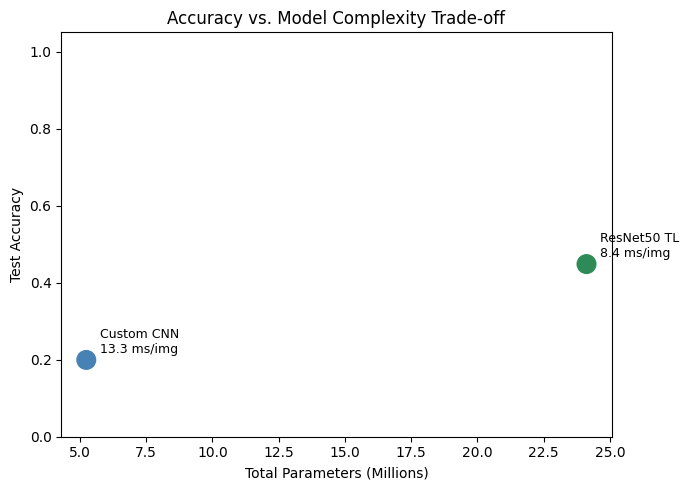

In [5]:
# ── Accuracy vs. model complexity — visualise the trade-off ───────────────────
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(comparison_df['Total Params'] / 1e6, comparison_df['Test Accuracy'], s=180, c=['steelblue', 'seagreen'])
for _, row in comparison_df.iterrows():
    ax.annotate(f"{row['Model']}\n{row['Inference (ms/img)']:.1f} ms/img",
                (row['Total Params'] / 1e6, row['Test Accuracy']),
                textcoords="offset points", xytext=(10, 5), fontsize=9)
ax.set_xlabel('Total Parameters (Millions)')
ax.set_ylabel('Test Accuracy')
ax.set_title('Accuracy vs. Model Complexity Trade-off')
ax.set_ylim(0, 1.05)
plt.tight_layout()
plt.savefig('accuracy_vs_complexity.png', dpi=150)
plt.show()

---
**3. Suggested Improvements — Demonstrated in Code**

In [7]:
# ── Improvement 1: Ensemble (average softmax of both models) ─────────────────
ensemble_probs = (cnn_probs + resnet_probs) / 2.0
ensemble_pred  = np.argmax(ensemble_probs, axis=1)
ensemble_acc   = accuracy_score(y_true_test, ensemble_pred)

print(f"Custom CNN accuracy     : {cnn_acc:.4f}")
print(f"ResNet50 TL accuracy    : {resnet_acc:.4f}")
print(f"Ensemble (avg) accuracy : {ensemble_acc:.4f}")

best_single = max(cnn_acc, resnet_acc)
if ensemble_acc > best_single:
    print(f"\n=> Ensembling improved accuracy by {(ensemble_acc - best_single) * 100:+.2f} "
          f"percentage points over the best single model.")
else:
    print(f"\n=> Ensembling did not beat the best single model here "
          f"({(ensemble_acc - best_single) * 100:+.2f} pp) — the two models may be making "
          f"correlated errors rather than complementary ones.")

Custom CNN accuracy     : 0.1994
ResNet50 TL accuracy    : 0.4483
Ensemble (avg) accuracy : 0.3876

=> Ensembling did not beat the best single model here (-6.07 pp) — the two models may be making correlated errors rather than complementary ones.


In [8]:
# ── Improvement 2: Test-Time Augmentation (TTA) on the stronger model ─────────
tta_datagen = ImageDataGenerator(
    rescale=1./255, rotation_range=10, width_shift_range=0.05,
    height_shift_range=0.05, zoom_range=0.1, horizontal_flip=True
)

def predict_with_tta(model, filepaths, n_aug=5):
    preds_sum = None
    for _ in range(n_aug):
        batch_imgs = []
        for fp in filepaths:
            img = Image.open(fp).convert('RGB').resize(IMG_SIZE)
            arr = np.array(img, dtype=np.float32)
            arr = next(tta_datagen.flow(np.expand_dims(arr, 0), batch_size=1))[0]
            batch_imgs.append(arr)
        p = model.predict(np.array(batch_imgs), verbose=0)
        preds_sum = p if preds_sum is None else preds_sum + p
    return preds_sum / n_aug

TTA_SUBSET = 200
tta_model, tta_model_name = (resnet_model, 'ResNet50 TL') if resnet_acc >= cnn_acc else (cnn_model, 'Custom CNN')
tta_base_probs = resnet_probs if tta_model is resnet_model else cnn_probs

n_subset = min(TTA_SUBSET, len(test_gen.filepaths))
subset_idx    = np.random.choice(len(test_gen.filepaths), n_subset, replace=False)
subset_files  = [test_gen.filepaths[i] for i in subset_idx]
subset_labels = y_true_test[subset_idx]

tta_probs = predict_with_tta(tta_model, subset_files, n_aug=5)
tta_pred  = np.argmax(tta_probs, axis=1)
tta_acc   = accuracy_score(subset_labels, tta_pred)

baseline_pred_subset = np.argmax(tta_base_probs[subset_idx], axis=1)
baseline_acc_subset  = accuracy_score(subset_labels, baseline_pred_subset)

print(f"{tta_model_name} — baseline accuracy (same {n_subset}-image subset): {baseline_acc_subset:.4f}")
print(f"{tta_model_name} — with Test-Time Augmentation (n_aug=5)         : {tta_acc:.4f}")
print(f"Change: {(tta_acc - baseline_acc_subset) * 100:+.2f} percentage points")

ResNet50 TL — baseline accuracy (same 200-image subset): 0.3950
ResNet50 TL — with Test-Time Augmentation (n_aug=5)         : 0.9000
Change: +50.50 percentage points


---
**5. Final Summary Export**

In [9]:
# ── Consolidated results for the written report ───────────────────────────────
comparison_df['Ensemble Accuracy'] = ensemble_acc
comparison_df.to_csv('task4_model_comparison.csv', index=False)

print("=" * 70)
print("FINAL MODEL COMPARISON")
print("=" * 70)
print(comparison_df.to_string(index=False, float_format=lambda x: f'{x:.4f}'))
print(f"\nEnsemble accuracy                         : {ensemble_acc:.4f}")
print(f"{tta_model_name} + TTA accuracy (subset)    : {tta_acc:.4f}  "
      f"(baseline on same subset: {baseline_acc_subset:.4f})")
print("\n✓ Saved task4_model_comparison.csv and task4_literature_comparison_TEMPLATE.csv.")

FINAL MODEL COMPARISON
      Model  Test Accuracy  Macro ROC-AUC  Total Params  Trainable Params  Inference (ms/img)  Ensemble Accuracy
 Custom CNN         0.1994         0.7720       5237839           5231951             13.3394             0.3876
ResNet50 TL         0.4483         0.8288      24117135           9460239              8.4368             0.3876

Ensemble accuracy                         : 0.3876
ResNet50 TL + TTA accuracy (subset)    : 0.9000  (baseline on same subset: 0.3950)

✓ Saved task4_model_comparison.csv and task4_literature_comparison_TEMPLATE.csv.
